# C02e — FZ-118 feature-guided intervention ladder (treatment-corrected v2)

This notebook tests whether published, interpretable rewriting interventions move five
locked AI texts toward the human region of the frozen FZ-118 representation while
preserving meaning and numbers.

## Corrections incorporated in this rebuild

- The previously reported “8 metrics explain 95% / 30 explain 99%” claim is retired.
  Those subsets retain high classification AUROC, but they do not reproduce 95%/99%
  of the frozen detector score on held-out rows.
- The top-8 and top-30 lists are retained as sparse diagnostic and routing sets.
- Candidate selection uses semantic preservation, raw 30-dimensional human kNN
  support, marginal collateral movement, and edit size—not a candidate detector score.
- A semantically valid active-stage rewrite is evaluated as the treatment; the
  original is only a fallback when that stage has no valid output.
- Exact ExtraTrees path contributions are computed only after the five selected rows
  are serialized and hashed.
- Files whose names contain `control`, `wrong_direction`, or `audit` are ignored in
  `candidate_inbox`.
- The frozen detector is loaded before any cell can reference it.

## Compute barrier

The notebook remains locked to five named micro cases. A five-case result is a
debugging result and never automatically authorizes a larger experiment.


In [1]:
from pathlib import Path
from collections import Counter
from difflib import SequenceMatcher
import gc
import hashlib
import importlib.util
import json
import pickle
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path("..")
C02B_OUT = ROOT / "results" / "causal" / "C02b_alison_reproduction_v2"
C02D_OUT = ROOT / "results" / "causal" / "C02d_fz118_neutralization"
OUT = ROOT / "results" / "causal" / "C02e_fz118_feature_guided"
INBOX = OUT / "candidate_inbox"
OUT.mkdir(parents=True, exist_ok=True)
INBOX.mkdir(parents=True, exist_ok=True)

SEED = 42
MICRO_SOURCE_IDS = [
    "chatgpt_00343",
    "chatgpt_01706",
    "chatgpt_02293",
    "chatgpt_04162",
    "chatgpt_04245",
]

# Change only after inspecting the preceding stage's five-case report.
ACTIVE_STAGE = "styleremix"
STAGE_ORDER = ["original", "styleremix", "alison", "dipper", "punctuation"]
if ACTIVE_STAGE not in STAGE_ORDER:
    raise ValueError(f"ACTIVE_STAGE must be one of {STAGE_ORDER}")

SEMANTIC_COSINE_FLOOR = 0.86
HUMAN_BAND = (0.05, 0.95)
HUMAN_SUPPORT_PERCENTILE_CEILING = 0.95

print("five-case lock:", MICRO_SOURCE_IDS)
print("active stage:", ACTIVE_STAGE)
print("output:", OUT)


five-case lock: ['chatgpt_00343', 'chatgpt_01706', 'chatgpt_02293', 'chatgpt_04162', 'chatgpt_04245']
active stage: styleremix
output: ../results/causal/C02e_fz118_feature_guided


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Lightweight dependencies

C02e does not download or run a rewriting model. It evaluates outputs from the
released method notebooks or from the stage CSV contract below, keeping expensive
generation isolated and resumable.


In [2]:
required = {
    "spacy": "spacy",
    "textstat": "textstat",
    "sentence_transformers": "sentence-transformers",
    "pyarrow": "pyarrow",
    "requests": "requests",
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Install in this kernel, restart, then rerun:")
    print("%pip install " + " ".join(sorted(set(missing))))
    raise RuntimeError("Missing packages: " + ", ".join(missing))

import requests
import spacy
import textstat

try:
    nlp = spacy.load("en_core_web_sm")
except OSError as exc:
    print("Run once, restart the kernel, then rerun this cell:")
    print("!python -m spacy download en_core_web_sm")
    raise exc

PUNCTUATION = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"),
    ("quote", '"'), ("lparen", "("), ("rparen", ")"),
    ("lbracket", "["), ("rbracket", "]"), ("newline", "\n"),
]

GOOGLE_WORDS_PATH = C02D_OUT / "google-10000-english.txt"
GOOGLE_WORDS_URL = (
    "https://raw.githubusercontent.com/first20hours/"
    "google-10000-english/master/google-10000-english.txt"
)
if not GOOGLE_WORDS_PATH.exists():
    response = requests.get(GOOGLE_WORDS_URL, timeout=60)
    response.raise_for_status()
    GOOGLE_WORDS_PATH.write_bytes(response.content)

google_words = [
    line.strip().lower()
    for line in GOOGLE_WORDS_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
GOOGLE_TOP = {
    100: set(google_words[:100]),
    1000: set(google_words[:1000]),
    10000: set(google_words[:10000]),
}
print("dependencies ready")


dependencies ready


## 2. Load the frozen feature contract and the five cases

Missing artifacts produce one compact status table. There are no row-count
assertions beyond the five explicit `source_id`s.


In [3]:
paths = {
    "feature_contract": C02D_OUT / "fz118_feature_contract.json",
    "original_features": C02D_OUT / "fz118_original_features.parquet",
    "corpus_roles": C02D_OUT / "fz118_corpus_roles.parquet",
    "frozen_detector": C02D_OUT / "fz118_frozen_detector.pkl",
}
path_status = pd.DataFrame([
    {"artifact": name, "path": str(path), "exists": path.exists()}
    for name, path in paths.items()
])
display(path_status)

if not path_status["exists"].all():
    missing = path_status.loc[~path_status["exists"], "artifact"].tolist()
    raise FileNotFoundError(
        "Missing C02d artifacts: " + ", ".join(missing)
        + ". Run C02d through detector freeze first."
    )

with paths["feature_contract"].open() as f:
    feature_contract = json.load(f)

FEATURE_NAMES = list(feature_contract["feature_names"])
FEATURE_BLOCKS = {k: list(v) for k, v in feature_contract["feature_blocks"].items()}
if len(FEATURE_NAMES) != 118:
    raise ValueError(f"Expected FZ-118 contract, got {len(FEATURE_NAMES)} features")

with paths["frozen_detector"].open("rb") as f:
    frozen_detector = pickle.load(f)

if not hasattr(frozen_detector, "estimators_"):
    raise TypeError(
        "This notebook's exact path decomposition requires the frozen ExtraTrees detector. "
        f"Loaded {type(frozen_detector).__name__}."
    )

original_features = pd.read_parquet(paths["original_features"])
corpus = pd.read_parquet(paths["corpus_roles"])
original_features["source_id"] = original_features["source_id"].astype(str)
corpus["source_id"] = corpus["source_id"].astype(str)

micro_ai = corpus[corpus["source_id"].isin(MICRO_SOURCE_IDS)].copy()
found = set(micro_ai["source_id"])
missing_ids = [x for x in MICRO_SOURCE_IDS if x not in found]
if missing_ids:
    raise KeyError(f"Five-case IDs absent from C02d corpus: {missing_ids}")

micro_ai = micro_ai.set_index("source_id").loc[MICRO_SOURCE_IDS].reset_index()
print("frozen detector:", type(frozen_detector).__name__)
display(micro_ai[["source_id", "pair_id", "class_name", "text"]])


,artifact,path,exists
0,feature_contract,/home/user/Downloads/TemporalContextResearch/...,True
1,original_features,/home/user/Downloads/TemporalContextResearch/...,True
2,corpus_roles,/home/user/Downloads/TemporalContextResearch/...,True
3,frozen_detector,/home/user/Downloads/TemporalContextResearch/...,True


frozen detector: ExtraTreesClassifier


,source_id,pair_id,class_name,text
0,chatgpt_00343,343,chatgpt,"In a recent incident, a local government offic..."
1,chatgpt_01706,1706,chatgpt,In a major shift from the traditional way of t...
2,chatgpt_02293,2293,chatgpt,"In a major political shakeup, Ireland has elec..."
3,chatgpt_04162,4162,chatgpt,The US and Chinese military have experienced a...
4,chatgpt_04245,4245,chatgpt,According to a new report released by the Amer...


## 3. Exact C02d FZ-118 extractor


In [4]:
def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector


toy = "One short sentence. Another sentence repeats one short phrase, and one short phrase returns."
toy_vector = extract_fz118(toy)
assert toy_vector.shape == (118,)
print("FZ-118 extractor smoke test passed")


FZ-118 extractor smoke test passed


## 4. Frozen sparse diagnostic sets

The order below is the previously frozen held-out ranking. The first eight and first
thirty coordinates are retained as sparse diagnostics. Their actual held-out score
reconstruction and classification AUROC are recomputed below; no 95%/99% fidelity
label is assumed.


In [5]:
TOP_8 = [
    "n_characters",
    "word_1gram_overlap_bin_0",
    "words_per_sentence",
    "punct_per_sentence_colon",
    "share_unique_words",
    "pos_2gram_overlap_bin_0",
    "punct_relative_lbracket",
    "pos_1gram_overlap_bin_9",
]
TOP_30 = TOP_8 + [
    "punct_per_sentence_lparen",
    "flesch_reading_ease",
    "word_2gram_overlap_bin_0",
    "word_2gram_overlap_bin_9",
    "share_difficult_words",
    "n_short_words",
    "share_stopwords",
    "punct_relative_quote",
    "pos_3gram_overlap_bin_9",
    "word_1gram_overlap_bin_1",
    "pos_3gram_overlap_bin_0",
    "punct_relative_comma",
    "n_difficult_words",
    "lix",
    "share_google_top10000",
    "pos_1gram_overlap_bin_5",
    "punct_relative_question",
    "n_sentences",
    "and_conjunction_word_bigram_overlap",
    "word_1gram_overlap_bin_6",
    "pos_2gram_overlap_bin_2",
    "word_1gram_overlap_bin_3",
]

absent = [name for name in TOP_30 if name not in FEATURE_NAMES]
if absent:
    raise KeyError(f"Metrics absent from the frozen contract: {absent}")

def feature_block(feature):
    idx = FEATURE_NAMES.index(feature)
    return next(name for name, indices in FEATURE_BLOCKS.items() if idx in indices)

METHOD_FOR_BLOCK = {
    "basic_absolute": "styleremix",
    "basic_relative": "styleremix",
    "paragraph": "styleremix",
    "readability": "styleremix",
    "pos_sentence_overlap": "alison",
    "word_sentence_overlap": "dipper",
    "lexical_diversity": "dipper",
    "punctuation_relative": "punctuation",
    "punctuation_per_sentence": "punctuation",
    "conjunction_overlap": "dipper",
}

metric_contract = pd.DataFrame({
    "rank": np.arange(1, 31),
    "metric": TOP_30,
    "diagnostic_set": ["top 8"] * 8 + ["top 30 extension"] * 22,
})
metric_contract["feature_block"] = metric_contract["metric"].map(feature_block)
metric_contract["controller"] = metric_contract["feature_block"].map(METHOD_FOR_BLOCK)
display(metric_contract)


,rank,metric,diagnostic_set,feature_block,controller
0,1,n_characters,top 8,basic_absolute,styleremix
1,2,word_1gram_overlap_bin_0,top 8,word_sentence_overlap,dipper
2,3,words_per_sentence,top 8,basic_relative,styleremix
3,4,punct_per_sentence_colon,top 8,punctuation_per_sentence,punctuation
4,5,share_unique_words,top 8,lexical_diversity,dipper
5,6,pos_2gram_overlap_bin_0,top 8,pos_sentence_overlap,alison
6,7,punct_relative_lbracket,top 8,punctuation_relative,punctuation
7,8,pos_1gram_overlap_bin_9,top 8,pos_sentence_overlap,alison
8,9,punct_per_sentence_lparen,top 30 extension,punctuation_per_sentence,punctuation
9,10,flesch_reading_ease,top 30 extension,readability,styleremix


## 5. Human bands from detector-training humans only

A metric has zero loss anywhere inside the human 5–95% interval. Outside it, loss
is distance to the nearer boundary in robust human-IQR units. This avoids forcing
every rewrite toward an artificial mean human document.


In [6]:
human_reference = original_features[
    original_features["fz_role"].eq("detector_train")
    & original_features["label"].eq(0)
].copy()
if len(human_reference) == 0:
    raise RuntimeError("No detector-training humans found in C02d artifacts.")

q_lo = human_reference[FEATURE_NAMES].quantile(HUMAN_BAND[0])
q_hi = human_reference[FEATURE_NAMES].quantile(HUMAN_BAND[1])
median = human_reference[FEATURE_NAMES].median()
iqr = (
    human_reference[FEATURE_NAMES].quantile(0.75)
    - human_reference[FEATURE_NAMES].quantile(0.25)
)
sd = human_reference[FEATURE_NAMES].std(ddof=1)
robust_scale = iqr.where(iqr.gt(1e-10), sd).where(lambda s: s.gt(1e-10), 1.0)

rank_weight = pd.Series(
    1.0 / np.log2(np.arange(2, 32)),
    index=TOP_30,
    dtype=float,
)
rank_weight = rank_weight / rank_weight.sum()

human_band_table = pd.DataFrame({
    "metric": TOP_30,
    "human_p05": q_lo[TOP_30].to_numpy(),
    "human_median": median[TOP_30].to_numpy(),
    "human_p95": q_hi[TOP_30].to_numpy(),
    "robust_scale": robust_scale[TOP_30].to_numpy(),
    "priority_weight": rank_weight[TOP_30].to_numpy(),
})
human_band_table.to_csv(OUT / "c02e_human_band_contract.csv", index=False)
display(human_band_table)


,metric,human_p05,human_median,human_p95,robust_scale,priority_weight
0,n_characters,1342.500000,1905.000000,2428.450000,485.500000,0.109151
1,word_1gram_overlap_bin_0,0.047500,0.222222,0.700135,0.260684,0.068867
2,words_per_sentence,7.129694,20.240385,29.894444,7.007305,0.054576
3,punct_per_sentence_colon,0.000000,0.000000,0.200000,0.083333,0.047009
4,share_unique_words,0.435714,0.551015,0.638032,0.093256,0.042226
5,pos_2gram_overlap_bin_0,0.000000,0.111111,0.727273,0.168627,0.038881
6,punct_relative_lbracket,0.000000,0.000000,0.000529,0.000203,0.036384
7,pos_1gram_overlap_bin_9,0.071429,0.285714,0.545960,0.189904,0.034433
8,punct_per_sentence_lparen,0.000000,0.055556,0.333333,0.125801,0.032858
9,flesch_reading_ease,30.819817,49.442519,67.179261,16.155881,0.031552


## 6. Build the candidate pool by `source_id`

Sources are additive: originals, checkpointed C02d candidates, ALISON outputs, and
completed files in `candidate_inbox`. Empty outputs are ignored. Audit and control
files are explicitly excluded so a negative-control rewrite cannot become a live
candidate merely because it is stored near the inbox.


In [7]:
candidate_parts = []
import_log = []

def canonical_family(operator):
    op = str(operator).strip().lower()
    if op == "original": return "original"
    if "styleremix" in op or op.startswith("sr_"): return "styleremix"
    if "alison" in op: return "alison"
    if "dipper" in op: return "dipper"
    if "punct" in op: return "punctuation"
    return "diagnostic_external"

def add_candidates(frame, source_label, text_column="text", operator_column="operator"):
    if frame is None or len(frame) == 0:
        import_log.append({"source": source_label, "imported": 0, "status": "empty"})
        return

    d = frame.copy()
    if "source_id" not in d or text_column not in d or operator_column not in d:
        import_log.append({
            "source": source_label,
            "imported": 0,
            "status": "missing columns",
        })
        return

    d["source_id"] = d["source_id"].astype(str)
    d = d[d["source_id"].isin(MICRO_SOURCE_IDS)].copy()
    d["text"] = d[text_column].fillna("").astype(str)
    d["operator"] = d[operator_column].fillna("").astype(str)
    d = d[d["text"].str.strip().ne("") & d["operator"].str.strip().ne("")]
    d["method_family"] = d["operator"].map(canonical_family)
    d["candidate_source"] = source_label
    d["text_hash"] = d["text"].map(
        lambda x: hashlib.sha256(x.encode("utf-8")).hexdigest()
    )
    candidate_parts.append(d[[
        "source_id", "operator", "method_family", "text",
        "text_hash", "candidate_source",
    ]])
    import_log.append({"source": source_label, "imported": len(d), "status": "ok"})

base = micro_ai[["source_id", "text"]].copy()
base["operator"] = "original"
add_candidates(base, "frozen originals")

external_path = C02D_OUT / "fz118_external_candidates.parquet"
if external_path.exists():
    add_candidates(pd.read_parquet(external_path), external_path.name)
else:
    import_log.append({"source": external_path.name, "imported": 0, "status": "absent"})

for path in sorted(C02D_OUT.glob("fz118_blackbox_return__*__n*.csv")):
    returned = pd.read_csv(path, keep_default_na=False)
    op_col = "service_id" if "service_id" in returned else "operator"
    add_candidates(returned, path.name, text_column="output_text", operator_column=op_col)

alison_path = C02B_OUT / "alison_outputs.parquet"
if alison_path.exists():
    alison = pd.read_parquet(alison_path)
    alison["operator"] = "alison_l15"
    text_col = "obfuscated_case_preserved" if "obfuscated_case_preserved" in alison else "text"
    add_candidates(alison, alison_path.name, text_column=text_col)
else:
    import_log.append({"source": alison_path.name, "imported": 0, "status": "absent"})

ignored_name_markers = ("control", "wrong_direction", "audit")
for path in sorted(INBOX.glob("*")):
    if any(marker in path.stem.lower() for marker in ignored_name_markers):
        import_log.append({
            "source": f"inbox/{path.name}",
            "imported": 0,
            "status": "ignored audit/control",
        })
        continue

    if path.suffix.lower() == ".csv":
        d = pd.read_csv(path, keep_default_na=False)
    elif path.suffix.lower() in {".parquet", ".pq"}:
        d = pd.read_parquet(path)
    else:
        continue

    text_col = "text" if "text" in d else "output_text"
    op_col = "operator" if "operator" in d else "method"
    add_candidates(
        d,
        f"inbox/{path.name}",
        text_column=text_col,
        operator_column=op_col,
    )

candidates = pd.concat(candidate_parts, ignore_index=True)
candidates = candidates.drop_duplicates(
    ["source_id", "operator", "text_hash"], keep="last"
)
candidates["candidate_id"] = (
    candidates["source_id"] + "|" + candidates["operator"] + "|"
    + candidates["text_hash"].str[:10]
)

display(pd.DataFrame(import_log))
display(candidates.groupby(["method_family", "operator"]).size().rename("n").to_frame())


,source,imported,status
0,frozen originals,5,ok
1,fz118_external_candidates.parquet,5,ok
2,fz118_blackbox_return__undetectable_ai_web_202...,5,ok
3,alison_outputs.parquet,5,ok
4,inbox/c02e_stage_01_styleremix_length_long_con...,0,ignored audit/control
5,inbox/c02e_stage_01_styleremix_routed.csv,1,ok
6,inbox/c02e_wrong_direction_length_long_chatgpt...,0,ignored audit/control


,,n
method_family,operator,
alison,alison_l15,5
diagnostic_external,undetectable_ai_web_2026_09_04,5
original,original,5
styleremix,styleremix,1


## 7. Semantic preservation screen and FZ extraction


In [8]:
from sentence_transformers import SentenceTransformer

semantic_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
original_by_id = micro_ai.set_index("source_id")["text"].astype(str)

orig_texts = [original_by_id[sid] for sid in candidates["source_id"]]
cand_texts = candidates["text"].astype(str).tolist()
orig_emb = semantic_model.encode(orig_texts, normalize_embeddings=True, show_progress_bar=True)
cand_emb = semantic_model.encode(cand_texts, normalize_embeddings=True, show_progress_bar=True)
candidates["semantic_cosine"] = np.sum(orig_emb * cand_emb, axis=1)

def numbers(text):
    return re.findall(r"(?<!\w)[+-]?(?:\d[\d,]*(?:\.\d+)?|\.\d+)%?", str(text))

candidates["numbers_preserved"] = [
    Counter(numbers(o)) == Counter(numbers(c))
    for o, c in zip(orig_texts, cand_texts)
]
candidates["lexical_change"] = [
    1.0 - SequenceMatcher(None, o, c).ratio()
    for o, c in zip(orig_texts, cand_texts)
]
candidates["semantic_valid"] = (
    candidates["text"].str.strip().ne("")
    & candidates["numbers_preserved"]
    & candidates["semantic_cosine"].ge(SEMANTIC_COSINE_FLOOR)
)

vectors = []
for text in tqdm(candidates["text"], desc="FZ-118 candidate features"):
    vectors.append(extract_fz118(text))
candidate_features = pd.DataFrame(vectors, columns=FEATURE_NAMES)
candidates = pd.concat([candidates.reset_index(drop=True), candidate_features], axis=1)

del semantic_model, orig_emb, cand_emb
gc.collect()
display(candidates.groupby("method_family").agg(
    n=("candidate_id", "size"),
    semantic_valid_rate=("semantic_valid", "mean"),
    mean_cosine=("semantic_cosine", "mean"),
    number_preservation=("numbers_preserved", "mean"),
))


FZ-118 candidate features: 100%|█████████████████████████████████████████████████████████| 16/16 [00:00<00:00, 30.54it/s]


,n,semantic_valid_rate,mean_cosine,number_preservation
method_family,,,,
alison,5,0.6,0.967921,0.6
diagnostic_external,5,0.4,0.937773,0.4
original,5,1.0,1.000000,1.0
styleremix,1,1.0,0.861777,1.0


## 8. Validate exact sparse forest-path reconstructions

For each tree, the positive-class probability at the root is the bias. Every edge on
a sample's root-to-leaf path contributes the child-minus-parent probability change to
the feature used at the parent split. Averaging across trees exactly reconstructs the
frozen ExtraTrees probability when all 118 contributions are summed.

The top-8 and top-30 tables below report what happens when only those frozen
coordinates are retained. These are diagnostics, not candidate-selection scores.


In [9]:
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.neighbors import NearestNeighbors

def exact_forest_probability_contributions(forest, X, desc="forest paths"):
    X = np.asarray(X, dtype=float)
    if not hasattr(forest, "estimators_"):
        raise TypeError(f"Expected a fitted forest, got {type(forest).__name__}")

    classes = list(forest.classes_)
    if 1 not in classes:
        raise ValueError(f"Positive class 1 absent from detector classes: {classes}")
    positive_index = classes.index(1)

    n_samples, n_features = X.shape
    contributions = np.zeros((n_samples, n_features), dtype=np.float64)
    bias = 0.0
    n_trees = len(forest.estimators_)

    for estimator in tqdm(forest.estimators_, desc=desc):
        tree = estimator.tree_
        node_value = tree.value[:, 0, :].astype(np.float64)
        denominator = node_value.sum(axis=1)
        node_probability = np.divide(
            node_value[:, positive_index],
            denominator,
            out=np.zeros_like(denominator, dtype=np.float64),
            where=denominator > 0,
        )
        bias += float(node_probability[0]) / n_trees

        for sample_index, row in enumerate(X):
            node = 0
            while tree.children_left[node] != tree.children_right[node]:
                feature_index = int(tree.feature[node])
                if row[feature_index] <= tree.threshold[node]:
                    child = int(tree.children_left[node])
                else:
                    child = int(tree.children_right[node])

                contributions[sample_index, feature_index] += (
                    node_probability[child] - node_probability[node]
                ) / n_trees
                node = child

    reconstructed = bias + contributions.sum(axis=1)
    expected = forest.predict_proba(X)[:, positive_index]
    if not np.allclose(reconstructed, expected, atol=1e-10, rtol=1e-10):
        raise AssertionError(
            "Forest path contributions do not exactly reconstruct predict_proba."
        )
    return float(bias), contributions, reconstructed

detector_train = original_features[
    original_features["fz_role"].eq("detector_train")
].copy()
detector_valid = original_features[
    original_features["fz_role"].eq("detector_validation")
].copy()

X_valid_full = detector_valid[FEATURE_NAMES].to_numpy(float)
valid_target = frozen_detector.predict_proba(X_valid_full)[:, 1]
valid_bias, valid_contributions, valid_reconstructed = (
    exact_forest_probability_contributions(
        frozen_detector,
        X_valid_full,
        desc="validation exact contributions",
    )
)

def sparse_reconstruction(contributions, bias, feature_names):
    indices = [FEATURE_NAMES.index(name) for name in feature_names]
    return bias + contributions[:, indices].sum(axis=1)

validation_rows = []
for explanation, feature_names in [
    ("8 exact raw-feature contributions", TOP_8),
    ("30 exact raw-feature contributions", TOP_30),
]:
    reconstructed = sparse_reconstruction(valid_contributions, valid_bias, feature_names)
    validation_rows.append({
        "explanation": explanation,
        "n_metrics": len(feature_names),
        "heldout_score_r2": r2_score(valid_target, reconstructed),
        "heldout_class_auc": roc_auc_score(detector_valid["label"], reconstructed),
        "full_frozen_auc": roc_auc_score(detector_valid["label"], valid_target),
    })

explanation_validation = pd.DataFrame(validation_rows)
display(explanation_validation)

X_human_full = human_reference[FEATURE_NAMES].to_numpy(float)
human_forest_bias, human_contributions_full, human_reconstructed_full = (
    exact_forest_probability_contributions(
        frozen_detector,
        X_human_full,
        desc="human exact contributions",
    )
)
human_median_contribution_full = np.median(human_contributions_full, axis=0)

human_reconstruction_bands = {}
human_band_rows = []
for label, feature_names in [("8 metrics", TOP_8), ("30 metrics", TOP_30)]:
    reconstructed = sparse_reconstruction(
        human_contributions_full,
        human_forest_bias,
        feature_names,
    )
    band = np.quantile(reconstructed, [0.05, 0.50, 0.95])
    human_reconstruction_bands[label] = band
    human_band_rows.append({
        "reconstruction": label,
        "human_p05": band[0],
        "human_median": band[1],
        "human_p95": band[2],
    })
display(pd.DataFrame(human_band_rows))

# Independent raw 30-dimensional joint-support diagnostic.
human_z30 = (
    human_reference[TOP_30].to_numpy(float)
    - median[TOP_30].to_numpy(float)
) / robust_scale[TOP_30].to_numpy(float)
human_neighbors = NearestNeighbors(n_neighbors=6).fit(human_z30)
human_loo_distance = human_neighbors.kneighbors(human_z30)[0][:, 1:].mean(axis=1)


validation exact contributions: 100%|█████████████████████████████████████████████████| 600/600 [00:02<00:00, 282.11it/s]


,explanation,n_metrics,heldout_score_r2,heldout_class_auc,full_frozen_auc
0,8 exact raw-feature contributions,8,0.496092,0.9747,0.9954
1,30 exact raw-feature contributions,30,0.753624,0.9894,0.9954


human exact contributions: 100%|██████████████████████████████████████████████████████| 600/600 [00:03<00:00, 194.24it/s]


,reconstruction,human_p05,human_median,human_p95
0,8 metrics,0.323688,0.381687,0.482452
1,30 metrics,0.225020,0.274692,0.445664


## 9. Score candidates without candidate detector access

Candidate selection uses semantic validity and proximity to combinations actually
observed among detector-training humans in the frozen top-30 raw-feature space.
Marginal 5–95% bands and full-surface collateral movement are descriptive tie-breakers.
No candidate forest probability or forest-path contribution is computed in this cell.


In [10]:
def outside_band_loss(frame, feature_names):
    X = frame[feature_names].to_numpy(float)
    lo = q_lo[feature_names].to_numpy(float)
    hi = q_hi[feature_names].to_numpy(float)
    scale = robust_scale[feature_names].to_numpy(float)
    return (np.maximum(lo - X, 0.0) + np.maximum(X - hi, 0.0)) / scale

candidate_z30 = (
    candidates[TOP_30].to_numpy(float)
    - median[TOP_30].to_numpy(float)
) / robust_scale[TOP_30].to_numpy(float)
candidates["human_knn_distance"] = human_neighbors.kneighbors(
    candidate_z30, n_neighbors=5
)[0].mean(axis=1)
candidates["human_knn_percentile"] = [
    float(np.mean(human_loo_distance <= distance))
    for distance in candidates["human_knn_distance"]
]
candidates["joint_human_support"] = candidates["human_knn_percentile"].le(
    HUMAN_SUPPORT_PERCENTILE_CEILING
)

top8_loss = outside_band_loss(candidates, TOP_8)
top30_loss = outside_band_loss(candidates, TOP_30)
full_loss = outside_band_loss(candidates, FEATURE_NAMES)

candidates["n_top8_marginal_outside"] = (top8_loss > 0).sum(axis=1)
candidates["n_top30_marginal_outside"] = (top30_loss > 0).sum(axis=1)
candidates["n_full_marginal_outside"] = (full_loss > 0).sum(axis=1)
candidates["mean_full_marginal_severity"] = full_loss.mean(axis=1)

audit_columns = [
    "source_id", "operator", "method_family", "semantic_valid",
    "semantic_cosine", "numbers_preserved", "lexical_change",
    "human_knn_distance", "human_knn_percentile", "joint_human_support",
    "n_top8_marginal_outside", "n_top30_marginal_outside",
    "n_full_marginal_outside", "mean_full_marginal_severity",
]
display(candidates[audit_columns].sort_values(
    [
        "source_id", "semantic_valid", "joint_human_support",
        "human_knn_percentile", "n_top30_marginal_outside",
        "mean_full_marginal_severity", "lexical_change",
    ],
    ascending=[True, False, False, True, True, True, True],
))


,source_id,operator,method_family,semantic_valid,semantic_cosine,numbers_preserved,lexical_change,human_knn_distance,human_knn_percentile,joint_human_support,n_top8_marginal_outside,n_top30_marginal_outside,n_full_marginal_outside,mean_full_marginal_severity
0,chatgpt_00343,original,original,True,1.000000,True,0.000000,2.740231,0.4000,True,2,2,8,0.053211
10,chatgpt_00343,alison_l15,alison,True,0.975662,True,0.707356,3.255302,0.6675,True,2,6,14,0.060157
5,chatgpt_00343,undetectable_ai_web_2026_09_04,diagnostic_external,True,0.957033,True,0.957097,3.703751,0.8125,True,3,5,13,0.106399
6,chatgpt_01706,undetectable_ai_web_2026_09_04,diagnostic_external,True,0.892603,True,0.942425,2.844958,0.4650,True,0,2,6,0.020836
1,chatgpt_01706,original,original,True,1.000000,True,0.000000,3.379900,0.7175,True,1,5,14,0.036105
11,chatgpt_01706,alison_l15,alison,True,0.963588,True,0.493955,3.411346,0.7300,True,3,6,13,0.040856
15,chatgpt_01706,styleremix,styleremix,True,0.861777,True,0.973517,4.716572,0.9525,False,2,7,20,0.130798
2,chatgpt_02293,original,original,True,1.000000,True,0.000000,2.872972,0.4775,True,1,2,5,0.020188
7,chatgpt_02293,undetectable_ai_web_2026_09_04,diagnostic_external,False,0.939138,False,0.777271,2.723045,0.3850,True,0,0,1,0.000669
12,chatgpt_02293,alison_l15,alison,False,0.963909,False,0.723455,3.179654,0.6375,True,2,3,10,0.037433


## 10. One-stage selection and pre-detector freeze

For a causal intervention probe, a semantically valid candidate from the active stage
is the treatment and must not be silently replaced by the original merely because a
pre-outcome diagnostic worsened. For each source, this cell therefore prefers a valid
active-stage candidate. Human-support and collateral diagnostics rank multiple valid
candidates within that stage. The original is used only when the active-stage output
is absent or semantically invalid.

The actual candidate detector probability remains uncomputed until the selected rows
are serialized and hashed.


In [11]:
eligible_families = set(STAGE_ORDER[: STAGE_ORDER.index(ACTIVE_STAGE) + 1])
eligible = candidates[candidates["method_family"].isin(eligible_families)].copy()

selection_sort = [
    "semantic_valid",
    "joint_human_support",
    "human_knn_percentile",
    "n_top30_marginal_outside",
    "mean_full_marginal_severity",
    "lexical_change",
]
selection_ascending = [False, False, True, True, True, True]

selected_rows = []
selection_reasons = []
for source_id in MICRO_SOURCE_IDS:
    source_rows = eligible[eligible["source_id"].eq(source_id)].copy()
    active_valid = source_rows[
        source_rows["method_family"].eq(ACTIVE_STAGE)
        & source_rows["semantic_valid"]
    ].sort_values(selection_sort, ascending=selection_ascending)

    if len(active_valid):
        chosen = active_valid.iloc[0]
        reason = "valid active-stage treatment"
    else:
        fallback = source_rows[
            ~source_rows["method_family"].eq(ACTIVE_STAGE)
        ].sort_values(selection_sort, ascending=selection_ascending)
        if len(fallback) == 0:
            raise RuntimeError(f"No fallback candidate for {source_id}")
        chosen = fallback.iloc[0]
        reason = "fallback: active-stage output absent or invalid"

    selected_rows.append(chosen)
    selection_reasons.append({"source_id": source_id, "selection_reason": reason})

selected = (
    pd.DataFrame(selected_rows)
    .set_index("source_id")
    .reindex(MICRO_SOURCE_IDS)
    .reset_index()
)
if selected["candidate_id"].isna().any():
    raise RuntimeError("At least one locked source ID has no original fallback.")
selected = selected.merge(
    pd.DataFrame(selection_reasons),
    on="source_id",
    how="left",
    validate="one_to_one",
)

baseline = candidates[candidates["method_family"].eq("original")].copy()
baseline = baseline.set_index("source_id").reindex(MICRO_SOURCE_IDS).reset_index()

freeze_columns = [
    "source_id", "candidate_id", "operator", "method_family", "text_hash", "text",
    "selection_reason",
    "semantic_cosine", "numbers_preserved", "semantic_valid", "lexical_change",
    "human_knn_distance", "human_knn_percentile", "joint_human_support",
    "n_top8_marginal_outside", "n_top30_marginal_outside",
    "n_full_marginal_outside", "mean_full_marginal_severity",
]
selected_frozen = selected[freeze_columns].copy()

frozen_path = OUT / f"c02e_micro5_selected_raw_joint_through_{ACTIVE_STAGE}.parquet"
selected_frozen.to_parquet(frozen_path, index=False)

freeze_bytes = (
    selected_frozen.sort_values("source_id").to_csv(index=False).encode("utf-8")
)
selection_sha256 = hashlib.sha256(freeze_bytes).hexdigest()
freeze_record = {
    "active_stage": ACTIVE_STAGE,
    "source_ids": MICRO_SOURCE_IDS,
    "selection_sha256": selection_sha256,
    "candidate_actual_detector_scores_computed_before_freeze": False,
    "selection_objective": (
        "prefer a semantically valid active-stage treatment; use frozen raw "
        "30-metric human kNN, marginal, and collateral diagnostics only to rank "
        "multiple treatments within the active stage"
    ),
    "semantic_cosine_floor": SEMANTIC_COSINE_FLOOR,
    "human_support_percentile_ceiling": HUMAN_SUPPORT_PERCENTILE_CEILING,
}
with (OUT / f"c02e_micro5_raw_joint_freeze_through_{ACTIVE_STAGE}.json").open("w") as f:
    json.dump(freeze_record, f, indent=2)

display(selected_frozen.drop(columns=["text"]))
print(json.dumps(freeze_record, indent=2))


,source_id,candidate_id,operator,method_family,text_hash,selection_reason,semantic_cosine,numbers_preserved,semantic_valid,lexical_change,human_knn_distance,human_knn_percentile,joint_human_support,n_top8_marginal_outside,n_top30_marginal_outside,n_full_marginal_outside,mean_full_marginal_severity
0,chatgpt_00343,chatgpt_00343|original|c02cdf976f,original,original,c02cdf976f888c5ddf5e02d615cef89673b462c191c2ba...,fallback: active-stage output absent or invalid,1.000000,True,True,0.000000,2.740231,0.4000,True,2,2,8,0.053211
1,chatgpt_01706,chatgpt_01706|styleremix|c37d29dac5,styleremix,styleremix,c37d29dac5632fa3249fe010d6b8ef8815e87470db5326...,valid active-stage treatment,0.861777,True,True,0.973517,4.716572,0.9525,False,2,7,20,0.130798
2,chatgpt_02293,chatgpt_02293|original|db2610cb4c,original,original,db2610cb4cf68bac7d30cd1c2174184bd2b92e6b0badce...,fallback: active-stage output absent or invalid,1.000000,True,True,0.000000,2.872972,0.4775,True,1,2,5,0.020188
3,chatgpt_04162,chatgpt_04162|original|004af6a98d,original,original,004af6a98d3464b7a10c64e9437d38db649a16ded1163a...,fallback: active-stage output absent or invalid,1.000000,True,True,0.000000,5.737309,0.9775,False,2,4,10,0.120427
4,chatgpt_04245,chatgpt_04245|original|c498fe7d8c,original,original,c498fe7d8c681aad35c2fc84126ba3bf22f6eb2cb9a058...,fallback: active-stage output absent or invalid,1.000000,True,True,0.000000,4.526143,0.9375,True,0,2,4,0.024887


{
  "active_stage": "styleremix",
  "source_ids": [
    "chatgpt_00343",
    "chatgpt_01706",
    "chatgpt_02293",
    "chatgpt_04162",
    "chatgpt_04245"
  ],
  "selection_sha256": "73df8f529e6c7f4a095e87436fc6e18351dda2f7bd68427b4202d83faffe902e",
  "candidate_actual_detector_scores_computed_before_freeze": false,
  "selection_objective": "prefer a semantically valid active-stage treatment; use frozen raw 30-metric human kNN, marginal, and collateral diagnostics only to rank multiple treatments within the active stage",
  "semantic_cosine_floor": 0.86,
  "human_support_percentile_ceiling": 0.95
}


## 11. Locked detector outcome and exact selected-row contributions

The selection hash already exists. Frozen detector probabilities and exact path
contributions are outcomes only and did not participate in candidate choice.


In [12]:
original_eval = baseline.set_index("source_id").loc[MICRO_SOURCE_IDS]
selected_eval = selected.set_index("source_id").loc[MICRO_SOURCE_IDS]

X_original_full = original_eval[FEATURE_NAMES].to_numpy(float)
X_selected_full = selected_eval[FEATURE_NAMES].to_numpy(float)
p_original = frozen_detector.predict_proba(X_original_full)[:, 1]
p_selected = frozen_detector.predict_proba(X_selected_full)[:, 1]

selected_forest_bias, selected_contributions_full, selected_reconstructed = (
    exact_forest_probability_contributions(
        frozen_detector,
        X_selected_full,
        desc="selected exact contributions",
    )
)
if not np.allclose(selected_reconstructed, p_selected, atol=1e-10, rtol=1e-10):
    raise AssertionError("Selected contribution reconstruction mismatch.")

locked_result = selected_frozen.drop(columns=["text"]).copy()
locked_result["original_fake_probability"] = p_original
locked_result["selected_fake_probability"] = p_selected
locked_result["fake_probability_change"] = p_selected - p_original
locked_result["classified_human_after"] = p_selected < 0.5
locked_result["selection_sha256"] = selection_sha256

contribution_rows = []
for sample_index, row in selected.reset_index(drop=True).iterrows():
    for metric_rank, metric in enumerate(TOP_30, start=1):
        feature_index = FEATURE_NAMES.index(metric)
        contribution = float(selected_contributions_full[sample_index, feature_index])
        human_contribution = float(human_median_contribution_full[feature_index])
        contribution_rows.append({
            "candidate_id": row["candidate_id"],
            "source_id": row["source_id"],
            "operator": row["operator"],
            "method_family": row["method_family"],
            "metric_rank": metric_rank,
            "metric": metric,
            "feature_block": feature_block(metric),
            "candidate_score_contribution": contribution,
            "median_human_score_contribution": human_contribution,
            "ai_score_contribution_gap": contribution - human_contribution,
        })

contribution_audit = pd.DataFrame(contribution_rows)
display(locked_result)
print("classified human after:", int(locked_result["classified_human_after"].sum()), "/ 5")
print("scores reduced:", int(locked_result["fake_probability_change"].lt(-1e-12).sum()), "/ 5")


selected exact contributions: 100%|██████████████████████████████████████████████████| 600/600 [00:00<00:00, 9282.21it/s]


,source_id,candidate_id,operator,method_family,text_hash,selection_reason,semantic_cosine,numbers_preserved,semantic_valid,lexical_change,...,joint_human_support,n_top8_marginal_outside,n_top30_marginal_outside,n_full_marginal_outside,mean_full_marginal_severity,original_fake_probability,selected_fake_probability,fake_probability_change,classified_human_after,selection_sha256
0,chatgpt_00343,chatgpt_00343|original|c02cdf976f,original,original,c02cdf976f888c5ddf5e02d615cef89673b462c191c2ba...,fallback: active-stage output absent or invalid,1.000000,True,True,0.000000,...,True,2,2,8,0.053211,0.946507,0.946507,2.220446e-16,False,73df8f529e6c7f4a095e87436fc6e18351dda2f7bd6842...
1,chatgpt_01706,chatgpt_01706|styleremix|c37d29dac5,styleremix,styleremix,c37d29dac5632fa3249fe010d6b8ef8815e87470db5326...,valid active-stage treatment,0.861777,True,True,0.973517,...,False,2,7,20,0.130798,0.938711,0.706441,-2.322707e-01,False,73df8f529e6c7f4a095e87436fc6e18351dda2f7bd6842...
2,chatgpt_02293,chatgpt_02293|original|db2610cb4c,original,original,db2610cb4cf68bac7d30cd1c2174184bd2b92e6b0badce...,fallback: active-stage output absent or invalid,1.000000,True,True,0.000000,...,True,1,2,5,0.020188,0.870103,0.870103,-2.220446e-16,False,73df8f529e6c7f4a095e87436fc6e18351dda2f7bd6842...
3,chatgpt_04162,chatgpt_04162|original|004af6a98d,original,original,004af6a98d3464b7a10c64e9437d38db649a16ded1163a...,fallback: active-stage output absent or invalid,1.000000,True,True,0.000000,...,False,2,4,10,0.120427,0.873883,0.873883,-2.220446e-16,False,73df8f529e6c7f4a095e87436fc6e18351dda2f7bd6842...
4,chatgpt_04245,chatgpt_04245|original|c498fe7d8c,original,original,c498fe7d8c681aad35c2fc84126ba3bf22f6eb2cb9a058...,fallback: active-stage output absent or invalid,1.000000,True,True,0.000000,...,True,0,2,4,0.024887,0.796793,0.796793,1.110223e-16,False,73df8f529e6c7f4a095e87436fc6e18351dda2f7bd6842...


classified human after: 0 / 5
scores reduced: 1 / 5


## 12. Signed exact-contribution heatmap and residual routing

Each cell is the selected row's exact ExtraTrees path contribution for one raw metric,
minus the median detector-training-human contribution for that metric:

- pale gray/white: close to the median-human contribution;
- red: pushes the detector toward AI;
- blue: pushes in the opposite direction and may represent humanward movement or
  overshoot.

The old black outside-band map is not used for routing.


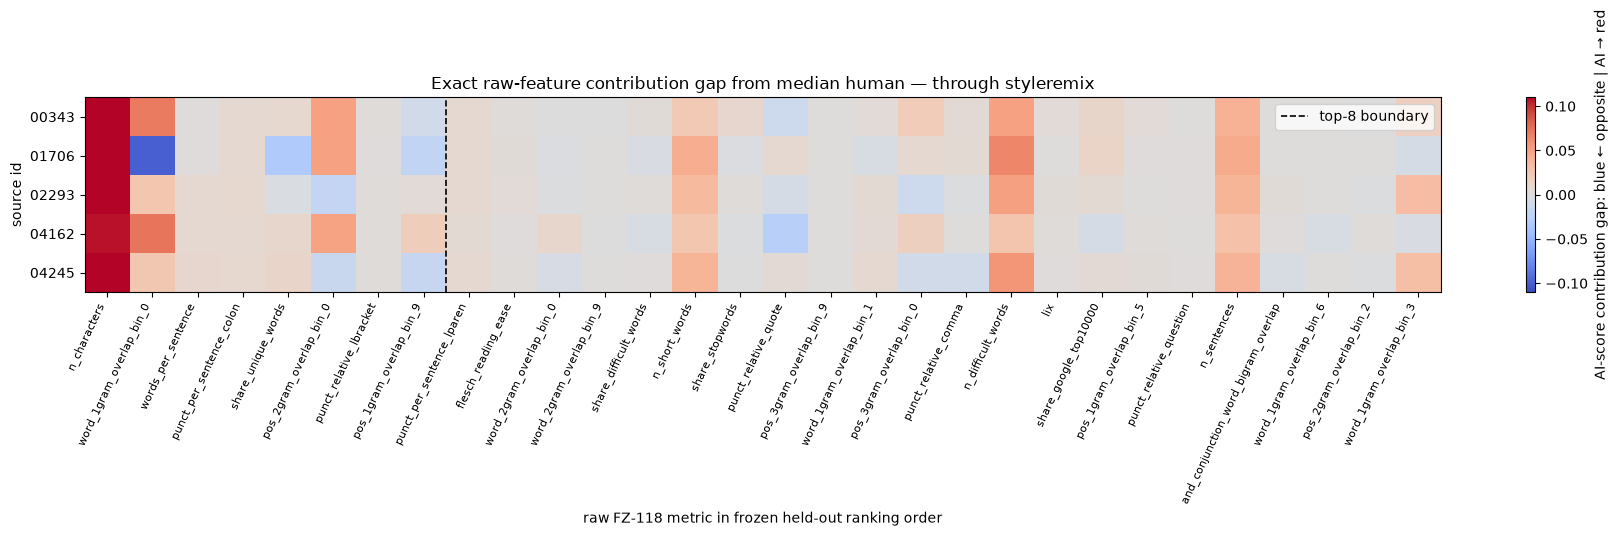

,source_id,metric_rank,metric,feature_block,ai_score_contribution_gap,recommended_next_method
0,chatgpt_00343,1,n_characters,basic_absolute,0.109976,styleremix
1,chatgpt_01706,1,n_characters,basic_absolute,0.118141,styleremix
2,chatgpt_02293,1,n_characters,basic_absolute,0.114596,styleremix
3,chatgpt_04162,1,n_characters,basic_absolute,0.106882,styleremix
4,chatgpt_04245,1,n_characters,basic_absolute,0.110122,styleremix


saved: ../results/causal/C02e_fz118_feature_guided/c02e_micro5_exact_contribution_heatmap_through_styleremix.png


In [13]:
from matplotlib.colors import TwoSlopeNorm

selected_contributions = contribution_audit.copy()
selected_contributions["short_id"] = selected_contributions["source_id"].str.replace(
    "chatgpt_", "", regex=False
)
contribution_heat = selected_contributions.pivot(
    index="short_id",
    columns="metric",
    values="ai_score_contribution_gap",
).reindex(
    index=[x.replace("chatgpt_", "") for x in MICRO_SOURCE_IDS],
    columns=TOP_30,
)

values = contribution_heat.to_numpy(float)
symmetric_limit = max(float(np.nanquantile(np.abs(values), 0.98)), 1e-4)

fig, ax = plt.subplots(figsize=(18, 4.8))
im = ax.imshow(
    values,
    aspect="auto",
    cmap="coolwarm",
    norm=TwoSlopeNorm(
        vmin=-symmetric_limit,
        vcenter=0.0,
        vmax=symmetric_limit,
    ),
)
ax.set_yticks(range(len(contribution_heat.index)), contribution_heat.index)
ax.set_xticks(
    range(len(contribution_heat.columns)),
    contribution_heat.columns,
    rotation=65,
    ha="right",
    fontsize=8,
)
ax.axvline(7.5, color="black", linestyle="--", linewidth=1.2, label="top-8 boundary")
ax.set_title(
    f"Exact raw-feature contribution gap from median human — through {ACTIVE_STAGE}"
)
ax.set_xlabel("raw FZ-118 metric in frozen held-out ranking order")
ax.set_ylabel("source id")
fig.colorbar(
    im,
    ax=ax,
    label="AI-score contribution gap: blue ← opposite | AI → red",
)
ax.legend(loc="upper right")
fig.tight_layout()

figure_path = OUT / f"c02e_micro5_exact_contribution_heatmap_through_{ACTIVE_STAGE}.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

positive = selected_contributions[
    selected_contributions["ai_score_contribution_gap"].gt(0)
].copy()
top_residual = (
    positive.sort_values("ai_score_contribution_gap", ascending=False)
    .groupby("source_id", as_index=False)
    .first()
)
top_residual["recommended_next_method"] = top_residual["feature_block"].map(
    METHOD_FOR_BLOCK
)

routing = pd.DataFrame({"source_id": MICRO_SOURCE_IDS}).merge(
    top_residual[[
        "source_id", "metric_rank", "metric", "feature_block",
        "ai_score_contribution_gap", "recommended_next_method",
    ]],
    on="source_id",
    how="left",
    validate="one_to_one",
)
routing["recommended_next_method"] = routing["recommended_next_method"].fillna(
    "none: no positive top-30 contribution gap"
)

display(routing)
print("saved:", figure_path)


## 13. Export only cases routed to the active method

The request is saved directly in the watched inbox. Fill `output_text` in place and
rerun from candidate import onward. Existing filled rows are preserved, and row order
is irrelevant.


In [14]:
current_family_rows = candidates[candidates["method_family"].eq(ACTIVE_STAGE)]
covered = set(current_family_rows["source_id"])
routed_ids = set(
    routing.loc[routing["recommended_next_method"].eq(ACTIVE_STAGE), "source_id"]
)
needed_ids = [sid for sid in MICRO_SOURCE_IDS if sid in routed_ids and sid not in covered]

previous_families = set(STAGE_ORDER[: STAGE_ORDER.index(ACTIVE_STAGE)])
previous = candidates[candidates["method_family"].isin(previous_families)].copy()

request_rows = []
for source_id in needed_ids:
    parent = previous[previous["source_id"].eq(source_id)].sort_values(
        selection_sort,
        ascending=selection_ascending,
    ).iloc[0]
    request_rows.append({
        "source_id": source_id,
        "operator": ACTIVE_STAGE,
        "input_text": parent["text"],
        "input_sha256": parent["text_hash"],
        "output_text": "",
        "settings": "RECORD EXACT RELEASE/MODEL/SETTINGS",
    })

request_path = INBOX / (
    f"c02e_stage_{STAGE_ORDER.index(ACTIVE_STAGE):02d}_{ACTIVE_STAGE}_routed.csv"
)
request_columns = [
    "source_id", "operator", "input_text", "input_sha256",
    "output_text", "settings",
]
request = pd.DataFrame(request_rows, columns=request_columns)

if request_path.exists():
    existing = pd.read_csv(request_path, keep_default_na=False)
    existing = existing[[c for c in request_columns if c in existing.columns]].copy()
    existing["source_id"] = existing["source_id"].astype(str)
    # Preserve all locked source rows so a completed but currently non-routed probe is
    # not silently deleted. Only known columns survive.
    existing = existing[existing["source_id"].isin(MICRO_SOURCE_IDS)]
    request = pd.concat([existing, request], ignore_index=True).drop_duplicates(
        "source_id", keep="first"
    )

if len(request):
    request = request.set_index("source_id").reindex(
        [sid for sid in MICRO_SOURCE_IDS if sid in set(request["source_id"])]
    ).reset_index()
    request.to_csv(request_path, index=False)
    still_needed = request["output_text"].astype(str).str.strip().eq("").sum()
    print("routed stage outputs still needed:", int(still_needed))
    print("saved in watched inbox:", request_path)
    display(request[["source_id", "input_sha256", "input_text", "output_text"]])
else:
    print("No unresolved case is currently routed to", ACTIVE_STAGE)


routed stage outputs still needed: 4
saved in watched inbox: ../results/causal/C02e_fz118_feature_guided/candidate_inbox/c02e_stage_01_styleremix_routed.csv


,source_id,input_sha256,input_text,output_text
0,chatgpt_00343,c02cdf976f888c5ddf5e02d615cef89673b462c191c2ba...,"In a recent incident, a local government offic...",
1,chatgpt_01706,1a28e515d17f3fb46bf6cfcd48fe805662525a5e050660...,In a major shift from the traditional way of t...,The Indian government has recently made a sign...
2,chatgpt_02293,db2610cb4cf68bac7d30cd1c2174184bd2b92e6b0badce...,"In a major political shakeup, Ireland has elec...",
3,chatgpt_04162,004af6a98d3464b7a10c64e9437d38db649a16ded1163a...,The US and Chinese military have experienced a...,
4,chatgpt_04245,c498fe7d8c681aad35c2fc84126ba3bf22f6eb2cb9a058...,According to a new report released by the Amer...,


## 14. Five-case gate and complete audit trail

The gate is deliberately strict. It reports the current five-case state but never
launches or authorizes a larger run automatically.


In [15]:
semantic_gate = bool(locked_result["semantic_valid"].all())
support_gate = bool(
    locked_result["human_knn_percentile"]
    .le(HUMAN_SUPPORT_PERCENTILE_CEILING)
    .sum() >= 4
)
frozen_gate = bool(locked_result["classified_human_after"].all())
active_stage_count = int(locked_result["method_family"].eq(ACTIVE_STAGE).sum())
coverage_gate = active_stage_count == len(MICRO_SOURCE_IDS)
MICRO_PASS = coverage_gate and semantic_gate and support_gate and frozen_gate

decision = {
    "active_stage": ACTIVE_STAGE,
    "selection_sha256": selection_sha256,
    "active_stage_coverage": f"{active_stage_count}/{len(MICRO_SOURCE_IDS)}",
    "active_stage_coverage_5_of_5": coverage_gate,
    "semantic_gate_5_of_5": semantic_gate,
    "joint_human_support_at_least_4_of_5": support_gate,
    "frozen_human_classification_5_of_5": frozen_gate,
    "micro_pass": MICRO_PASS,
    "larger_stage_authorized": False,
    "instruction": (
        "MICRO PASS. Inspect outputs, then manually preregister the next sample size."
        if MICRO_PASS else
        "MICRO BLOCKED. Run only the routed intervention requests; do not scale."
    ),
}

candidates[
    audit_columns + ["candidate_id", "text_hash", "candidate_source"]
].to_csv(
    OUT / f"c02e_micro5_candidate_audit_through_{ACTIVE_STAGE}.csv",
    index=False,
)
contribution_audit.to_parquet(
    OUT / f"c02e_micro5_exact_raw_contributions_through_{ACTIVE_STAGE}.parquet",
    index=False,
)
locked_result.to_csv(
    OUT / f"c02e_micro5_locked_result_through_{ACTIVE_STAGE}.csv",
    index=False,
)
routing.to_csv(
    OUT / f"c02e_micro5_routing_through_{ACTIVE_STAGE}.csv",
    index=False,
)
explanation_validation.to_csv(
    OUT / "c02e_exact_sparse_explanation_validation.csv",
    index=False,
)
with (OUT / f"c02e_micro5_decision_through_{ACTIVE_STAGE}.json").open("w") as f:
    json.dump(decision, f, indent=2)

print(json.dumps(decision, indent=2))


{
  "active_stage": "styleremix",
  "selection_sha256": "73df8f529e6c7f4a095e87436fc6e18351dda2f7bd68427b4202d83faffe902e",
  "active_stage_coverage": "1/5",
  "active_stage_coverage_5_of_5": false,
  "semantic_gate_5_of_5": true,
  "joint_human_support_at_least_4_of_5": false,
  "frozen_human_classification_5_of_5": false,
  "micro_pass": false,
  "larger_stage_authorized": false,
  "instruction": "MICRO BLOCKED. Run only the routed intervention requests; do not scale."
}


## Interpretation map

| Residual block | First intervention | Role in this notebook |
|---|---|---|
| length, sentence length, function words, readability | StyleRemix | Directed short-length causal probe |
| POS adjacent-sentence overlap | ALISON | POS-overlap intervention |
| lexical diversity and word overlap | DIPPER | Lexical/reordering intervention |
| punctuation rates | constrained punctuation pass | Minimal punctuation intervention |

Heatmap interpretation: red means a positive AI-score contribution gap, blue means an
opposite-direction gap that may be humanward or overshoot, and pale gray/white is near
the median-human contribution. In the retired outside-band heatmap, black meant zero
marginal band violation; it never meant globally human-classified.

Relevant methods:

- Fisher et al., [StyleRemix](https://aclanthology.org/2024.emnlp-main.241/), EMNLP 2024.
- Xie et al., [ALISON](https://ojs.aaai.org/index.php/AAAI/article/view/26877), AAAI 2023.
- Krishna et al., [DIPPER](https://arxiv.org/abs/2301.00774).

None establishes control over the full FZ-118 joint distribution. This remains a
five-case mechanism probe, not a general detector-evasion claim.


## Appendix A. Prepare the released short-length StyleRemix adapter

The released checkpoint contains about 4.23 GB of tensors even though its rank-16
`q_proj`/`v_proj` LoRA contains only 6,815,744 parameters. The preparation cell below
creates an inference-only local checkpoint containing exactly the 128 LoRA tensors.

It is disabled by default. Set `PREPARE_SHORT_ADAPTER = True` only if the local slim
adapter is absent.


In [16]:
PREPARE_SHORT_ADAPTER = False

SLIM_STYLE_REMIX_ADAPTER = Path(
    "/home/user/Downloads/TemporalContextResearch/"
    "reproduction/results/causal/C02e_fz118_feature_guided/"
    "local_adapters/length_short_lora_only"
)

if PREPARE_SHORT_ADAPTER:
    import shutil
    import torch
    from huggingface_hub import snapshot_download
    from safetensors import safe_open
    from safetensors.torch import save_file

    adapter_snapshot = Path(snapshot_download(
        "hallisky/lora-length-short-llama-3-8b",
        allow_patterns=["adapter_config.json", "adapter_model.safetensors"],
    ))
    source_weights = adapter_snapshot / "adapter_model.safetensors"
    SLIM_STYLE_REMIX_ADAPTER.mkdir(parents=True, exist_ok=True)

    kept_tensors = {}
    with safe_open(source_weights, framework="pt", device="cpu") as source:
        for key in source.keys():
            if ".lora_A." in key or ".lora_B." in key:
                kept_tensors[key] = source.get_tensor(key).to(
                    dtype=torch.float16
                ).contiguous()

    n_tensors = len(kept_tensors)
    n_parameters = sum(t.numel() for t in kept_tensors.values())
    assert n_tensors == 128, n_tensors
    assert n_parameters == 6_815_744, n_parameters

    shutil.copy2(
        adapter_snapshot / "adapter_config.json",
        SLIM_STYLE_REMIX_ADAPTER / "adapter_config.json",
    )
    save_file(
        kept_tensors,
        SLIM_STYLE_REMIX_ADAPTER / "adapter_model.safetensors",
        metadata={"format": "pt"},
    )
    del kept_tensors
    gc.collect()

adapter_config_path = SLIM_STYLE_REMIX_ADAPTER / "adapter_config.json"
adapter_weights_path = SLIM_STYLE_REMIX_ADAPTER / "adapter_model.safetensors"
print("adapter directory:", SLIM_STYLE_REMIX_ADAPTER)
print("config ready:", adapter_config_path.is_file())
print("weights ready:", adapter_weights_path.is_file())
if adapter_weights_path.is_file():
    print("weights MiB:", round(adapter_weights_path.stat().st_size / 2**20, 2))


adapter directory: ../results/causal/C02e_fz118_feature_guided/local_adapters/length_short_lora_only
config ready: True
weights ready: True
weights MiB: 13.02


## Appendix B. Generate exactly one short-length StyleRemix probe

This cell is disabled by default and processes only the first blank row in the routed
request. It validates all paths before loading the 8B model and refuses to start unless
at least 7.2 GiB of the 7.62-GiB GPU is free. Restart the kernel before enabling it.

After generation, set `RUN_ONE_STYLEREMIX = False`, restart the kernel, and rerun the
analysis from the top.


In [17]:
RUN_ONE_STYLEREMIX = False

if RUN_ONE_STYLEREMIX:
    import os
    os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

    import torch
    from peft import PeftModel
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

    STYLE_REMIX_MODEL = "meta-llama/Meta-Llama-3-8B"
    STYLE_REMIX_ADAPTER = str(SLIM_STYLE_REMIX_ADAPTER)
    request_path = INBOX / "c02e_stage_01_styleremix_routed.csv"

    required_files = [
        Path(STYLE_REMIX_ADAPTER) / "adapter_config.json",
        Path(STYLE_REMIX_ADAPTER) / "adapter_model.safetensors",
        request_path,
    ]
    missing = [str(path) for path in required_files if not path.is_file()]
    if missing:
        raise FileNotFoundError("Missing preflight files:\n" + "\n".join(missing))

    request = pd.read_csv(request_path, keep_default_na=False)
    pending = request[request["output_text"].astype(str).str.strip().eq("")]
    if len(pending) == 0:
        raise RuntimeError("No blank StyleRemix request row remains.")

    row_index = pending.index[0]
    row = request.loc[row_index]
    input_text = str(row["input_text"])
    print("processing:", [row["source_id"]])

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    free_gib = free_bytes / 2**30
    print(f"GPU before loading: {free_gib:.2f} / {total_bytes / 2**30:.2f} GiB free")
    if free_gib < 7.2:
        raise RuntimeError("GPU is not clean. Restart the kernel before model loading.")

    tokenizer = AutoTokenizer.from_pretrained(
        STYLE_REMIX_MODEL,
        use_fast=True,
        add_bos_token=True,
        add_eos_token=False,
        padding_side="left",
    )
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    converted_text = f"### Original: {input_text}\n ### Rewrite:"
    tokenized_input = tokenizer(converted_text, add_special_tokens=True)
    if len(tokenized_input["input_ids"]) > 2048:
        raise ValueError("Formatted input exceeds StyleRemix's 2048-token limit.")

    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_quant_storage=torch.uint8,
    )
    base = AutoModelForCausalLM.from_pretrained(
        STYLE_REMIX_MODEL,
        quantization_config=quantization_config,
        dtype=torch.float16,
        device_map={"": 0},
        low_cpu_mem_usage=True,
        attn_implementation="sdpa",
    )
    model = PeftModel.from_pretrained(
        base,
        STYLE_REMIX_ADAPTER,
        adapter_name="length_short",
        is_trainable=False,
        autocast_adapter_dtype=False,
        low_cpu_mem_usage=True,
    )
    model.set_adapter("length_short", inference_mode=True)
    model.eval()

    # StyleRemix was trained on this exact delimiter format. A generic instruction
    # prompt can produce an immediate EOS token with the released adapter.
    inputs = tokenizer(
        converted_text,
        return_tensors="pt",
        max_length=2048,
        truncation=True,
    ).to("cuda:0")
    input_token_count = int(inputs["input_ids"].shape[1])
    max_new_tokens = min(1024, max(128, int(input_token_count * 1.15)))
    min_new_tokens = min(48, max(24, input_token_count // 12))

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            min_new_tokens=min_new_tokens,
            do_sample=True,
            temperature=1.0,
            top_p=0.95,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            cache_implementation="offloaded",
        )

    continuation = generated[0, inputs["input_ids"].shape[1]:]
    rewrite = tokenizer.decode(continuation, skip_special_tokens=True).strip()
    if not rewrite:
        raise RuntimeError("StyleRemix returned an empty rewrite.")

    request.loc[row_index, "output_text"] = rewrite
    request.loc[row_index, "settings"] = (
        "base=Meta-Llama-3-8B 4bit NF4; adapter=length-short rank16 FP16; "
        "official_prompt='### Original: ... ### Rewrite:'; min_new_tokens=dynamic; "
        "temperature=1.0; top_p=0.95; cache=offloaded"
    )
    request.to_csv(request_path, index=False)
    print(
        "saved", row["source_id"],
        "| input characters:", len(input_text),
        "| output characters:", len(rewrite),
    )

    del model, base, tokenizer, inputs, generated
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    print("saved:", request_path)
else:
    print("StyleRemix runner disabled; set RUN_ONE_STYLEREMIX = True after a kernel restart.")


StyleRemix runner disabled; set RUN_ONE_STYLEREMIX = True after a kernel restart.
